<a href="https://colab.research.google.com/github/LucasAbCV/procesamientoDelHabla/blob/main/PH_TP2_LucasAbruzzo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Trabajo práctico obligatorio N2: Procesamiento de archivos PDF
Alumno: Lucas Abruzzo

Para el trabajo de procesamiento de PDF se elgió el documento científico de https://arxiv.org/pdf/2610.23237 titulado "X-Splat: Unified Gaussian Splatting for Joint RGB and X-ray 3D Reconstruction". El documento aborda la reconstrucción 3D mediante el uso de la técnica de Gaussian Splatting combinando imagenes comunes (RGB) y radiografías.

Las técnicas anteriores de GS permitían obtener objetos 3D digitales de manera superficial (uso de imágenes RGB), pero con las radiografías, se puede trabajar sobre las etsructuras internas

#Librerías


In [ ]:
!pip install pymupdf


In [ ]:
import requests                         #Peticiones HTTP
import fitz                             #Abrir y extraer PDF
import textwrap                         #Formatear texto
import pandas as pd                     #Trabajar con tabla de datos
import re                               #Expresiones regulares
import nltk                             #Procesamiento de lenguaje natural
from nltk.corpus import stopwords       #StopWords
from nltk.tokenize import word_tokenize #Tokenizacion
from collections import Counter         #Conteo de elementos
import matplotlib.pyplot as plt         #Graficar



#Fuente: las librerìas fueron añadidas a medida que se fueron resolviendo las demàs celdas. Algunas son resultados de prompts, pero fueron agrupadas al principio, por un tema de organizaciòn.

In [ ]:
nltk.download("punkt")                  #Modelo de tokenizaciòn
nltk.download("punkt_tab")
nltk.download("stopwords")              #StopWords

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

#Descarga PDF
Descarga: Utilizando las librerías requests o urllib, descarga un archivo PDF desde un enlace público (por ejemplo, un artículo científico de arXiv o un reporte institucional).

No puede usar el mismo pdf o enlace que otra persona ya haya presentado en el foro. El PDF elegido debe contener texto extraible, no deben ser páginas escaneadas tipo imagen.

In [ ]:
url = "https://arxiv.org/pdf/2610.23237"                                 #URL paper
ruta = "GaussianSplat.pdf"                                               #Ruta

#Descarga el contenido de la URL
respuesta = requests.get(url, timeout=30)

#Lanza error si falla la descarga
respuesta.raise_for_status()
with open(ruta, "wb") as f:
    f.write(respuesta.content)

print(f"Descargado: {ruta} ({len(respuesta.content) / 1024:.1f} KB)")



#Fuente: prompt "descarga el usando request el pdf del siguiente link https://arxiv.org/pdf/2610.23237 "

Descargado: GaussianSplat.pdf (19099.9 KB)


#Metadata
Inspección: Muestra por pantalla los metadatos del archivo: título, autor, número de páginas y software de creación.

Sugerencia: Puedes utilizar librerías como PyMuPDF (fitz) o PyPDF2.

In [ ]:
#Apertura PDF
doc = fitz.open("GaussianSplat.pdf")
#Metadata
print(doc.metadata)


#Impresión ordenada de los metadatos
print("---------Metadata-----------")
print(f"Formato: {doc.metadata["format"]}")
print(f"Título: {doc.metadata["title"]}")
print(f"Autor/es: {doc.metadata["author"]}")
print(f"Materia/tópico: {doc.metadata["subject"]}")
print(f"Palabras claves: {doc.metadata["keywords"]}")
print(f"Creador: {doc.metadata["creator"]}")
print(f"Productor: {doc.metadata["producer"]}")
print(f"Fecha: {doc.metadata["creationDate"]}")
print(f"Número de páginas: {doc.page_count}")

#Fuente: prompt como puedo extraer metadata de un pdf usando pymupdf. El formato es un diccionario, por lo que adapte la impresión de pantalla a algo mas amigable.


{'format': 'PDF 1.7', 'title': 'X-Splat: Unified Gaussian Splatting for Joint RGB and X-ray 3D Reconstruction', 'author': 'Wangze Xu; Chu Zhou; Mae Yamaguchi; Linrui Dai; I-Chao Shen; Takashi Ijiri; Imari Sato', 'subject': '-  Computing methodologies  ->  Point-based models.Reconstruction.', 'keywords': '3D Gaussian splatting, cross-modal 3D reconstruction, X-ray tomography, novel view synthesis', 'creator': 'arXiv GenPDF (tex2pdf:07e334b)', 'producer': 'pikepdf 8.15.1', 'creationDate': "D:20261019010225+00'00'", 'modDate': "D:20261019010225+00'00'", 'trapped': '', 'encryption': None}
---------Metadata-----------
Formato: PDF 1.7
Título: X-Splat: Unified Gaussian Splatting for Joint RGB and X-ray 3D Reconstruction
Autor/es: Wangze Xu; Chu Zhou; Mae Yamaguchi; Linrui Dai; I-Chao Shen; Takashi Ijiri; Imari Sato
Materia/tópico: -  Computing methodologies  ->  Point-based models.Reconstruction.
Palabras claves: 3D Gaussian splatting, cross-modal 3D reconstruction, X-ray tomography, novel v

#Extracción cruda PDF

Extracción cruda: Extrae el texto del PDF. Identifica la función de la librería elegida que te ayuda en esta tarea y te permite ver el texto extraído lo más crudo posible.

Para el PDF se continúa utilizando PyMuPDF (fitz). Repr() muestra el texto como realmente esta contenido, pudiendo obtener una representaciòn cruda importante para el resto del trabajo.

Por defecto, print() imprime todo el texto en una sola lìnea, por lo que se usa textwrap.fill(texto,n) para poder visualizarlo con un màximo de n caracteres por lìnea en Colab.

In [ ]:
#Opciones de extracción
flags = (
    fitz.TEXT_PRESERVE_WHITESPACE                             #Mantiene espacios y tabulaciones
    | fitz.TEXT_PRESERVE_LIGATURES                            #Mantiene ligadoras (posibles problemas al traer texto del formato LaTeX, usado en papers)
)

#Recorrido de las páginas Extraccián de sus textos
#text pide texto plano
#flags hace uso de las opciones establecidas anteriormente
#sort = False conserva el orden interno del documento
paginas = [p.get_text("text", flags=flags, sort=False) for p in doc]
crudo = "".join(paginas)                                                    #Une las pàginas

#En "crudo.txt" guarda el texto. Usa el modo escritura, evita problemas con tildes,ñ y sìmbolos. newline="" impide que python cambie los saltos de lìnea
with open("crudo.txt", "w", encoding="utf-8", newline="") as f:
    f.write(crudo)

#Impresión de la cantidad de caracteres y de los espacios
print(len(crudo), "caracteres,", crudo.count(" "), "espacios")


#Fuente: utilicé el prompt " a parir de un documento abierto con PyMuPDF (fitz), puedes generar un script que extraiga el texto lo màs crudo posible. Esto quiere decir, conservar los espacios en blanco, tabulaciones y saltos de lìnea.
#Luego guarda el texto".

88881 caracteres, 10773 espacios


In [ ]:
#Impresión texto crudo
print(textwrap.fill(repr(crudo), width=100))


#Fuente: utilicé el prompt: "¿como puedo imprimir el texto, incluyendo los separadores y evitando la impresiòn absolutamente horizontal de Colab?"

'X-Splat: Unified Gaussian Splatting for Joint RGB and X-ray 3D\nReconstruction\nWANGZE XU, The
University of Tokyo, Japan\nCHU ZHOU, National Institute of Informatics, Japan\nMAE YAMAGUCHI, The
University of Tokyo, Japan\nLINRUI DAI, The University of Tokyo, Japan\nI-CHAO SHEN, The University
of Tokyo, Japan\nTAKASHI IJIRI, Shibaura Institute of Technology, Japan\nIMARI SATO, National
Institute of Informatics, Japan and The University of Tokyo,
Japan\nOurs\n3DGS\nR!-Gaussian\nInsideOut"\nUnified Gaussian\nAppearance\nInternal\nAppearance\nInte
rnal\nAppearance\nInternal\nAppearance\nInternal\nRGB\n&\nX-ray\nSplatting\nRGB Sensor\nX-ray
Sensor\nVisible Light\nX-ray\nReflection\nPenetration\nFig. 1. We propose X-Splat, a unified
representation where one set of Gaussian primitives carries both reflective (RGB) and absorptive
(X-ray) attributes,\nsimultaneously capturing external appearance and internal structure while
enabling joint optimization. Single-modality specialists (3DGS [Kerbl 

Análisis de separadores: Observa y describe cómo están separados los párrafos, las secciones y los capítulos.

Identificación de caracteres: ¿Qué caracteres especiales funcionan como separadores de línea o de bloque en este archivo específico? (Ej: \n, \r, \t o secuencias de espacios).


Para eso, seleccionamos algunos de los separadores màs utilizados y verificamos cuantos hay de cada uno. Es importante aclarar de que las imagenes no se conservan en el texto.

In [ ]:
#Se definen algunos separadores en interes
separadores = {
    "\\n  (salto de línea)": "\n",
    "\\r  (retorno de carro)": "\r",
    "\\t  (tabulación)": "\t",
    "\\x0c (salto de página)": "\x0c",
    "\\x08 (retroceso)": "\x08",
    "espacio normal": " ",
    "\\xa0 (NBSP)": "\xa0",
    "\\u200b (ancho cero)": "\u200b",
    "\\xad (guion blando)": "\xad",
}

#Imprime la cantidad de cada separador
for nombre, caracter in separadores.items():
    print(f"{nombre:28} {crudo.count(caracter)}")

#Fuente: se utilizó el prompt: "dado un diccionario ¿como imprimo la cantidad de elementos del mismo en un texto?"


\n  (salto de línea)         2569
\r  (retorno de carro)       0
\t  (tabulación)             0
\x0c (salto de página)       0
\x08 (retroceso)             0
espacio normal               10773
\xa0 (NBSP)                  0
\u200b (ancho cero)          0
\xad (guion blando)          0


Cada párrafo se separa por saltos de línea (a veces más de uno). Lo mismo sucede con las secciones y las páginas. En algunos casos parece haber tabulaciones, pero si se toma alguna herramienta de ediciónd e PDF se puede notar que fue construido a partir de la ubicación de bloques de texto. Es decir, algunos de los resultados visuales o reglas de redacción son sustituídos por la manipulación de la ubicación de esos bloques.

Podemos observar:

* Para separar palabras se utilizan espacios
* Para separar tìtulos, subtìtulos y pàrrafos y secciones se utilizan saltos de lìnea.



#Tabla

Busca una página en el PDF que contenga una tabla de datos.

Extrae dicha tabla y conviértela en un DataFrame de Pandas.

In [ ]:
pagina = doc[6]   #Hay una tabla en la pàgina 7 (ìndice 6)

tablas = pagina.find_tables()   #Busca la tabla
print(len(tablas.tables), "tablas encontradas")   #Imprime la cantidad de tablas encontradas


df = tablas[0].to_pandas()    #Convierte la tabla a un Dataframe de Pandas.
df                            #Muestra el DataFrame


#Fuente: se utilizó el prompt: " crea un algoritmo que tenga una tabla de datos". Luego ajusté el índice acorde al PDF, hice la conversión a DataFrame y lo imprimí

1 tablas encontradas


,Subject:,Col1,Matryoshka,Col3,Col4,Pharaoh,Col6,Col7,Skull,Col9,Col10,Toy Gun,Col12,Col13,Average,Col15
0,(a) RGB Novel View Synthesis,,,,,,,,,,,,,,,
1,Metric:,PSNR↑,SSIM↑,LPIPS↓,PSNR↑,SSIM↑,LPIPS↓,PSNR↑,SSIM↑,LPIPS↓,PSNR↑,SSIM↑,LPIPS↓,PSNR↑,SSIM↑,LPIPS↓
2,3DGS (MVS init) [Kerbl et al . 2023],29.56,0.9643,0.0393,29.64,0.9719,0.0291,31.08,0.9670,0.0475,34.54,0.9871,0.0133,31.20,0.9726,0.0323
3,3DGS (FDK init) [Kerbl et al . 2023],29.75,0.9628,0.0408,29.51,0.9707,0.0298,30.97,0.9660,0.0501,34.55,0.9870,0.0136,31.20,0.9716,0.0336
4,InsideOut† [Lee et al . 2025],18.13,0.8836,0.1522,21.78,0.9039,0.0927,19.57,0.9003,0.1497,25.39,0.9609,0.0481,21.22,0.9122,0.1107
5,Ours,30.37,0.9693,0.0354,30.89,0.9756,0.0272,32.42,0.9713,0.0433,36.68,0.9900,0.0114,32.59,0.9765,0.0293
6,(b) X-ray Reconstruction,,,,,,,,,,,,,,,
7,Metric:,2D-PSNR↑,2D-SSIM↑,3D-PSNR↑,2D-PSNR↑,2D-SSIM↑,3D-PSNR↑,2D-PSNR↑,2D-SSIM↑,3D-PSNR↑,2D-PSNR↑,2D-SSIM↑,3D-PSNR↑,2D-PSNR↑,2D-SSIM↑,3D-PSNR↑
8,FDK [Feldkamp et al . 1984],31.93,0.9019,24.47,42.92,0.9829,35.65,31.84,0.7997,25.91,28.77,0.9317,28.25,33.86,0.9040,28.57
9,R2-Gaussian [Zha et al . 2024],48.20,0.9940,33.35,52.33,0.9984,42.28,49.56,0.9963,37.09,48.96,0.9966,40.28,49.76,0.9963,38.25


#Limpieza


In [ ]:
corte = 6   # posición donde empieza la segunda tabla

tabla_a = df.iloc[:corte]    #Crea la primera tabla con las filas hasta el corte
tabla_b = df.iloc[corte:]    #Crea la segunda tabla a partir de la fila de corte
tabla_a = tabla_a[2:].reset_index(drop=True)
tabla_b = tabla_b.iloc[2:].reset_index(drop=True)
tabla_a                      #Muestra la primera tabla


#Fuente:se utilizò el prompt: "genera un algoritmo para devidir una tabla en 2 a partir de un umbral y reiniciando los ìndices"

,Subject:,Col1,Matryoshka,Col3,Col4,Pharaoh,Col6,Col7,Skull,Col9,Col10,Toy Gun,Col12,Col13,Average,Col15
0,3DGS (MVS init) [Kerbl et al . 2023],29.56,0.9643,0.0393,29.64,0.9719,0.0291,31.08,0.9670,0.0475,34.54,0.9871,0.0133,31.20,0.9726,0.0323
1,3DGS (FDK init) [Kerbl et al . 2023],29.75,0.9628,0.0408,29.51,0.9707,0.0298,30.97,0.9660,0.0501,34.55,0.9870,0.0136,31.20,0.9716,0.0336
2,InsideOut† [Lee et al . 2025],18.13,0.8836,0.1522,21.78,0.9039,0.0927,19.57,0.9003,0.1497,25.39,0.9609,0.0481,21.22,0.9122,0.1107
3,Ours,30.37,0.9693,0.0354,30.89,0.9756,0.0272,32.42,0.9713,0.0433,36.68,0.9900,0.0114,32.59,0.9765,0.0293


In [ ]:
tabla_b                      #Muestra la segunda tabla

,Subject:,Col1,Matryoshka,Col3,Col4,Pharaoh,Col6,Col7,Skull,Col9,Col10,Toy Gun,Col12,Col13,Average,Col15
0,FDK [Feldkamp et al . 1984],31.93,0.9019,24.47,42.92,0.9829,35.65,31.84,0.7997,25.91,28.77,0.9317,28.25,33.86,0.9040,28.57
1,R2-Gaussian [Zha et al . 2024],48.20,0.9940,33.35,52.33,0.9984,42.28,49.56,0.9963,37.09,48.96,0.9966,40.28,49.76,0.9963,38.25
2,InsideOut† [Lee et al . 2025],48.20,0.9940,33.35,52.33,0.9984,42.28,49.56,0.9963,37.09,48.96,0.9966,40.28,49.76,0.9963,38.25
3,Ours,48.34,0.9941,33.39,52.51,0.9983,42.13,49.72,0.9963,36.90,48.69,0.9964,40.25,49.81,0.9963,38.16


In [ ]:

#Obtiene una versión simplificada y clara de los modelos (limpia los strings)
metodos = (tabla_a["Subject:"]
          .str.replace(r"\[.*?\]", "", regex=True)
          .str.replace("†", "", regex=False)
          .str.strip())

#Extrae los sujetos( teniendo en cuenta que estan centrado cada 3 columnas)
sujetos = tabla_a.columns[2::3].tolist()
# ['Matryoshka', 'Pharaoh', 'Skull', 'Toy Gun', 'Average']

#Contruye los bloques reorganizados por sujeto
bloques = []
for i, suj in enumerate(sujetos):
    bloque = tabla_a.iloc[:, 1 + 3*i : 4 + 3*i].copy()   #3 columnas del sujeto
    bloque.columns = ["PSNR", "SSIM", "LPIPS"]           #Renombra las columnas con los nombres de la lista
    bloque.insert(0, "Sujeto", suj)                      #Inserta la columna llamada "Sujeto" con los valores de suj
    bloque.insert(1, "Método", metodos.values)           #Inserta la columna llamada "Mètodo"  con los valores de los mètodos
    bloques.append(bloque)                               #Añade el bloque a la lista de bloques

#Uniòn de todas las partes
largo_a = pd.concat(bloques, ignore_index=True)
largo_a[["PSNR", "SSIM", "LPIPS"]] = largo_a[["PSNR", "SSIM", "LPIPS"]].apply(          #Convierte los valores a tipo numèrico
    pd.to_numeric, errors="coerce")

largo_a                                                                                 #Muestra el resultado respecto a la primera tabla


#Fuente: Se pasó una captura de una de las 2 tablas y se describió en el prompt la nueva estructura: "es importante para el estudio, conservar las métricas como variables, pero es necesario que el sujeto también sea una variable (asumiendo
#que se va a repetir 3 veces cada uno en la nueva columna). Lo mismo debe suceder con el método".

,Sujeto,Método,PSNR,SSIM,LPIPS
0,Matryoshka,3DGS (MVS init),29.56,0.9643,0.0393
1,Matryoshka,3DGS (FDK init),29.75,0.9628,0.0408
2,Matryoshka,InsideOut,18.13,0.8836,0.1522
3,Matryoshka,Ours,30.37,0.9693,0.0354
4,Pharaoh,3DGS (MVS init),29.64,0.9719,0.0291
5,Pharaoh,3DGS (FDK init),29.51,0.9707,0.0298
6,Pharaoh,InsideOut,21.78,0.9039,0.0927
7,Pharaoh,Ours,30.89,0.9756,0.0272
8,Skull,3DGS (MVS init),31.08,0.9670,0.0475
9,Skull,3DGS (FDK init),30.97,0.9660,0.0501


In [ ]:
#Se repite el proceso para la segunda tabla
metodos = (tabla_b["Subject:"]
          .str.replace(r"\[.*?\]", "", regex=True)
          .str.replace("†", "", regex=False)
          .str.strip())

sujetos = tabla_b.columns[2::3].tolist()
bloques = []
for i, suj in enumerate(sujetos):
    bloque = tabla_b.iloc[:, 1 + 3*i : 4 + 3*i].copy()
    bloque.columns = ["2D-PSNR", "2D-SSIM", "3D-PSNR"]
    bloque.insert(0, "Sujeto", suj)
    bloque.insert(1, "Método", metodos.values)
    bloques.append(bloque)

largo_b = pd.concat(bloques, ignore_index=True)
largo_b[["2D-PSNR", "2D-SSIM", "3D-PSNR"]] = largo_b[["2D-PSNR", "2D-SSIM", "3D-PSNR"]].apply(
    pd.to_numeric, errors="coerce")
largo_b

,Sujeto,Método,2D-PSNR,2D-SSIM,3D-PSNR
0,Matryoshka,FDK,31.93,0.9019,24.47
1,Matryoshka,R2-Gaussian,48.20,0.9940,33.35
2,Matryoshka,InsideOut,48.20,0.9940,33.35
3,Matryoshka,Ours,48.34,0.9941,33.39
4,Pharaoh,FDK,42.92,0.9829,35.65
5,Pharaoh,R2-Gaussian,52.33,0.9984,42.28
6,Pharaoh,InsideOut,52.33,0.9984,42.28
7,Pharaoh,Ours,52.51,0.9983,42.13
8,Skull,FDK,31.84,0.7997,25.91
9,Skull,R2-Gaussian,49.56,0.9963,37.09


#Análisis de frecuencias
Elige una página que contenga únicamente texto narrativo, usa la biblioteca nltk o spacy  y realiza lo siguiente:

* Tokenización: Extrae el texto y conviértelo a minúsculas.
* Limpieza: Elimina las stop words (palabras funcionales sin peso semántico como "el", "de", "y") y signos de puntuación.
* Visualización: Genera un gráfico de barras que muestre las 15 palabras más frecuentes en esa página. ¿ Te surgieron en esta visualización tokens que también considerarías stop words? Comenta y justifica.

In [ ]:
pagina = doc[5]                   #Página compuesta solo por texto

texto = pagina.get_text().lower() #Se extrae el texto y se lo pasa a minúscula

#Fuente: se reutiliza la obtención de la página del enunciado anterior buscando alguna que solo tenga texto. Lo mismo sucede con la obtención del texto y pasaje a minúscula


In [ ]:
#Tokenizaciòn según el ingles
tokens = word_tokenize(texto, language="english")
#Conserva las palabras que no son números, caracteres extraños
tokens = [t for t in tokens if t.isalpha()]
tokens



#Fuente: se adapta la implementación vista ne clases anteriores

['wangze',
 'xu',
 'chu',
 'zhou',
 'mae',
 'yamaguchi',
 'linrui',
 'dai',
 'shen',
 'takashi',
 'ijiri',
 'and',
 'imari',
 'sato',
 'experiments',
 'experimental',
 'setup',
 'datasets',
 'we',
 'evaluate',
 'our',
 'method',
 'on',
 'two',
 'datasets',
 'covering',
 'nine',
 'scenes',
 'the',
 'first',
 'is',
 'the',
 'insideout',
 'dataset',
 'lee',
 'et',
 'al',
 'which',
 'vides',
 'four',
 'scenes',
 'matryoshka',
 'pharaoh',
 'skull',
 'and',
 'toy',
 'gun',
 'with',
 'paired',
 'rgb',
 'photographs',
 'and',
 'ct',
 'volumes',
 'the',
 'ond',
 'which',
 'we',
 'refer',
 'to',
 'as',
 'the',
 'flower',
 'insect',
 'dataset',
 'contains',
 'two',
 'flower',
 'scenes',
 'tulip',
 'eustoma',
 'from',
 'ijiri',
 'et',
 'al',
 'and',
 'three',
 'insect',
 'scenes',
 'acquired',
 'from',
 'prepared',
 'specimens',
 'all',
 'with',
 'paired',
 'ct',
 'volumes',
 'to',
 'evaluate',
 'all',
 'baselines',
 'under',
 'identical',
 'acquisition',
 'geometry',
 'we',
 'follow',
 'the',
 'p

In [ ]:
#StopWords
stop_en = set(stopwords.words("english"))
#Conserva los que no sean stopwords
limpios = [t for t in tokens if t not in stop_en]


#Fuente: se adaptó el algoritmo presentado en clases anteriores

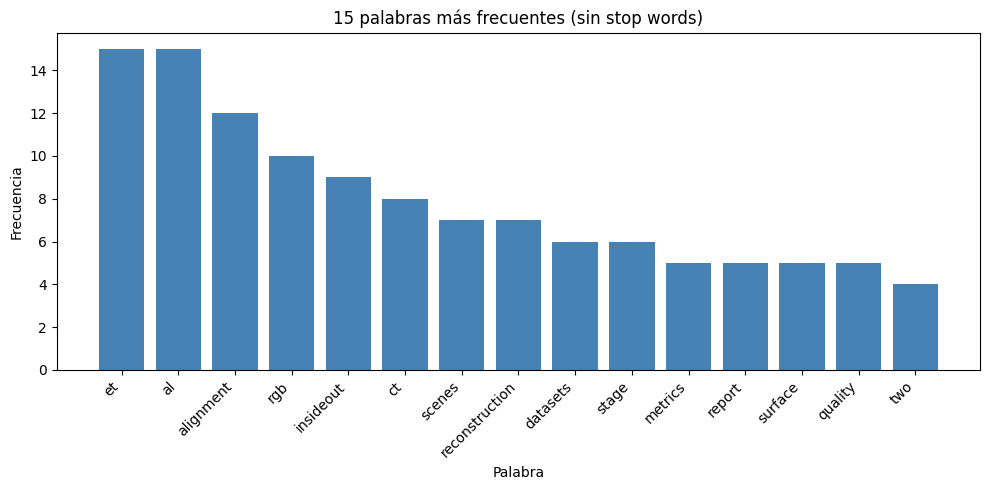

In [ ]:
frecuencias = Counter(limpios).most_common(15)  #Cuenta cuantas veces aparece cada token armando un diccionario. Y luego devuelve los 15 con mayor frecuencia de mayor a menor
palabras, conteos = zip(*frecuencias)           #En palabras se almacenan las palabras del resultado anterior, y en conteo, sus frecuencias

#Gràfico
plt.figure(figsize=(10, 5))
plt.bar(palabras, conteos, color="steelblue")
plt.xticks(rotation=45, ha="right")
plt.title("15 palabras más frecuentes (sin stop words)")
plt.xlabel("Palabra")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()



#Fuente: se utilizó el prompt: "crea un algoritmo que permita graficar las n palabras más frecuentes"

A partir de los resultados se pueden ver algunas palabras que no aportan significado. Por ejemplo "et" y "al" que vienen del latín et alii, y significa "y otros". Es muy usada en las citas cuando hay varios autores. Esto es común en documentos científicos. En el caso de "ct", refiere a "computed tomography", por ende, aunque será mejor tener la expresión completa, sigue siendo útil.

Respecto al "two" suele haber puntos a favor y en contra, algunas stopwords suelen incluir los números, y otras no. Esto se debe a que los números en este formato, dependen mucho del contexto.